In [1]:
import pandas as pd
import numpy as np
from dbfread import DBF
import socket
#import fdb
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
%run ../funciones/functions.ipynb

In [3]:
table = DbfReader('//svrinverpalmas/produc/basetdinamica/exportado.dbf')
table.read_dbf()
df = table.data

In [4]:
# Versión completa desde 2010 hasta 2026
dflonas = unir_tablas('//svrinverpalmas/produc/ld_bcult/',
      ['lonas2010.dbf','lonas2011.dbf','lonas2012.dbf','lonas2013.dbf','lonas2014.dbf','lonas2015.dbf',
       'lonas2016.dbf','lonas2017.dbf','lonas2018.dbf','lonas2019.dbf','lonas2020.dbf','lonas2021.dbf',
       'lonas2022.dbf','lonas2023.dbf','lonas2024.dbf','lonas2025.dbf','lonas2026.dbf']
     )

dfpto = unir_tablas('//svrinverpalmas/produc/ld_bcult/',
      ['pto2010.dbf','pto2011.dbf','pto2012.dbf','pto2013.dbf','pto2014.dbf','pto2015.dbf',
       'pto2016.dbf','pto2017.dbf','pto2018.dbf','pto2019.dbf','pto2020.dbf','pto2021.dbf',
       'pto2022.dbf','pto2023.dbf','pto2024.dbf','pto2025.dbf','pto2026.dbf']
     )

dfplantas = unir_tablas('//svrinverpalmas/produc/ld_bcult/',
      ['pblo2010.dbf','pblo2011.dbf','pblo2012.dbf','pblo2013.dbf','pblo2014.dbf','pblo2015.dbf',
       'pblo2016.dbf','pblo2017.dbf','pblo2018.dbf','pblo2019.dbf','pblo2020.dbf','pblo2021.dbf',
       'pblo2022.dbf','pblo2023.dbf','pblo2024.dbf','pblo2025.dbf','pblo2026.dbf']
     )

dfareas = unir_tabla_areas('//svrinverpalmas/produc/ld_bcult/',
      ['cre2010.dbf','cre2011.dbf','cre2012.dbf','cre2013.dbf','cre2014.dbf','cre2015.dbf',
       'cre2016.dbf','cre2017.dbf','cre2018.dbf','cre2019.dbf','cre2020.dbf','cre2021.dbf',
       'cre2022.dbf','cre2023.dbf','cre2024.dbf','cre2025.dbf','cre2026.dbf']
     )

In [5]:
dfpto.rename({'fecha_p':'fecha'},axis=1,inplace=True)

In [6]:
dfareas['ano'] = dfareas['ano'].astype(int)

In [7]:
df_areas = dfareas.groupby(['finca','flor','ano','mes'])['metros'].sum().reset_index()

In [8]:
dflonas['fecha'] = pd.to_datetime(dflonas['fecha'])
dfpto['fecha'] = pd.to_datetime(dfpto['fecha'])
dfplantas['fecha'] = pd.to_datetime(dfplantas['fecha'],errors='coerce')


In [9]:
dflonas['ano'] = dflonas.fecha.dt.year
dflonas['mes'] = dflonas.fecha.dt.month
#Ajustar presupuesto
dfpto['ano'] = dfpto.fecha.dt.year
dfpto['mes'] = dfpto.fecha.dt.month
#Ajustar plantas por mes y año
dfplantas = dfplantas.groupby(['flor','finca','fecha'])['matas'].sum().reset_index()
dfplantas['ano'] = dfplantas.fecha.dt.year
dfplantas['mes'] = dfplantas.fecha.dt.month

In [10]:
#dfplantas = dfplantas.groupby(['flor','finca','fecha']).sum().reset_index()
# Encontrar el índice de la fecha máxima en cada grupo
idx_max_fecha = dfplantas.groupby(['flor', 'finca', 'ano', 'mes'])['fecha'].idxmax()
# Filtrar el DataFrame original usando los índices encontrados
df_plantas = dfplantas.loc[idx_max_fecha]

In [11]:
df_prod = dflonas.pivot_table(
    index=['ano','mes','flor'],
    columns = ['finca'],
    values='lonas',
    aggfunc=np.sum
).reset_index()

In [12]:
df_pto = dfpto.groupby(
    ['ano','mes','flor','finca']
)['produccion'].sum().reset_index()

df_pto.rename({'produccion':'presupuesto'},axis=1,inplace=True)

In [13]:
df_matas = df_plantas.groupby(
    ['ano','mes','flor','finca'],
)['matas'].sum().reset_index()

In [14]:
df.sample()

,ano,mes,flor,grado,produccion,zusa,zeuro,zotros,desechos,bajas_nac,...,haprod,ha,producto,expble,fmt2prod_b,fmt2prod_n,fmt2xble_b,fmt2xble_n,nacional,_nullflags
2783,2021,9,CLA,STD,133572.73,68256.0,80350.0,0.0,0.0,0.0,...,12.38,16.51,CLAVEL ,133572.73,1.08,0.81,1.08,0.81,0.0,b'\x01'


In [15]:
df.query("ano=='2017'")

,ano,mes,flor,grado,produccion,zusa,zeuro,zotros,desechos,bajas_nac,...,haprod,ha,producto,expble,fmt2prod_b,fmt2prod_n,fmt2xble_b,fmt2xble_n,nacional,_nullflags
1574,2017,1,CLA,FAN,1418207.77,1195816.0,258665.0,2380.0,0.0,0.00,...,12.38,16.51,CLAVEL ,1418207.77,11.46,8.59,11.46,8.59,0.0,b'\x01'
1575,2017,1,CLA,NAL,283437.60,0.0,0.0,269719.0,81795.0,75786.89,...,12.38,16.51,CLAVEL ,0.00,2.29,1.72,0.00,0.00,283437.6,b'\x01'
1576,2017,1,CLA,SEL,697705.89,517161.0,297945.0,268.0,20.0,0.00,...,12.38,16.51,CLAVEL ,697705.89,5.64,4.23,5.64,4.23,0.0,b'\x01'
1577,2017,1,CLA,SHR,102038.20,30000.0,71760.0,0.0,200.0,0.00,...,12.38,16.51,CLAVEL ,102038.20,0.82,0.62,0.82,0.62,0.0,b'\x01'
1578,2017,1,CLA,STD,274539.54,216200.0,55100.0,0.0,0.0,0.00,...,12.38,16.51,CLAVEL ,274539.54,2.22,1.66,2.22,1.66,0.0,b'\x01'
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1819,2017,12,ROS,040,100317.00,104442.0,0.0,0.0,0.0,0.00,...,4.03,4.69,ROSAS ,100317.00,2.49,2.14,2.49,2.14,0.0,b'\x01'
1820,2017,12,ROS,050,82730.00,117840.0,6440.0,0.0,4550.0,0.00,...,4.03,4.69,ROSAS ,82730.00,2.05,1.76,2.05,1.76,0.0,b'\x01'
1821,2017,12,ROS,060,-2990.00,10070.0,440.0,0.0,2800.0,0.00,...,4.03,4.69,ROSAS ,-2990.00,-0.07,-0.06,-0.07,-0.06,0.0,b'\x01'
1822,2017,12,ROS,080,7220.00,2180.0,5040.0,0.0,0.0,0.00,...,4.03,4.69,ROSAS ,7220.00,0.18,0.15,0.18,0.15,0.0,b'\x01'


In [16]:
df = df[(df.grado!='') & (df.produccion>0) ].reset_index(drop=True)

In [17]:
df_prod = df_prod.fillna(0)
df_pto = df_pto.fillna(0)
df_matas = df_matas.fillna(0)

#Aporte segpun tiqueteados
df_prod['aporte001'] = df_prod['001'] / (df_prod['001'] + df_prod['002'])
df_prod['aporte002'] = df_prod['002'] / (df_prod['001'] + df_prod['002'])

In [18]:
df['%grado'] = df.groupby(['ano','mes','flor'])['produccion'].transform( lambda x: x / x.sum() )

In [19]:
df['ano'] = df['ano'].astype('int')

In [20]:
df.query("ano==2010").pivot_table(index=['flor','grado'],columns='mes',values='%grado').to_excel("c:/Users/Estadistica/Downloads/datos2024.xlsx")

In [21]:
df.dtypes[:2]

ano    int64
mes    int64
dtype: object

In [22]:
df_pto.head()

,ano,mes,flor,finca,presupuesto
0,1970,1,ROC,001,0
1,1970,1,ROS,001,0
2,1970,1,flo,fin,0
3,2010,1,CLA,001,1784426
4,2010,1,CLA,002,1143833


In [23]:
df_matas.head()

,ano,mes,flor,finca,matas
0,2010,1,CLA,001,1679233
1,2010,1,CLA,002,1193362
2,2010,1,CM0,001,567412
3,2010,1,CM0,002,912428
4,2010,1,ROC,001,606573


In [24]:
df_areas.head()

,finca,flor,ano,mes,metros
0,001,CLA,2010,1,88000
1,001,CLA,2010,2,88000
2,001,CLA,2010,3,88000
3,001,CLA,2010,4,88000
4,001,CLA,2010,5,88000


In [25]:
df['vta_nal'] = df['ingnaciona'] - (df['produccion'] - (df['zusa'] + df['zeuro'] + df['zotros'] - df['bajas_a']))

In [26]:
df['ano'] = df['ano'].astype(int)

In [27]:
df1 = df.groupby(['ano','mes','flor','grado']).agg(
    {'produccion':np.sum,'desechos':np.sum,'bajas_nac':np.sum,'compras':np.sum,'obsequios':np.sum,'inicial':np.sum,'expble':np.sum,'exptdo':np.sum,'vta_nal':np.sum,'desechos':np.sum,'bajas_nac':np.sum,'nacional':np.sum,'%grado':np.mean}
).reset_index()

In [28]:
df_real_unir = df.groupby(['ano','mes','flor']).agg({'produccion':'sum','expble':'sum','exptdo':'sum'}).reset_index()
df_pto_unir = df_pto.groupby(['ano','mes','flor']).agg({'presupuesto':'sum'}).reset_index()
df_pto_vs_real = (
    pd.merge(
        df_real_unir,df_pto_unir,on=['ano','mes','flor'],how='outer'
    )
)

In [29]:
df_pto_vs_real.ano.max()

np.int64(2026)

In [30]:
df_pto_vs_real = df_pto_vs_real.query("ano>=2023")

# 1. Definir las condiciones
condiciones = [
    (df_pto_vs_real['flor'] == 'CLA'),
    (df_pto_vs_real['flor'] == 'CM0')
]

# 2. Definir los resultados (restar 8%, restar 5% y el resto 10%)
resultados = [
    df_pto_vs_real['presupuesto'] * 0.92,  # CLA: -8%
    df_pto_vs_real['presupuesto'] * 0.95   # CM0: -5%
]

# 3. Crear la columna usando np.select(condiciones, resultados, valor_por_defecto)
# El valor por defecto aplica el -10% (multiplicar por 0.90)
df_pto_vs_real['pto_exportable'] = np.select(condiciones, resultados, default=df_pto_vs_real['presupuesto'] * 0.90)

# Opcional: Redondear a enteros si son tallos
df_pto_vs_real['pto_exportable'] = df_pto_vs_real['pto_exportable'].round(0)


In [31]:
df_pto_vs_real = df_pto_vs_real.rename(
    columns={
        'produccion':'real_produccion',
        'expble': 'real_exportable',
        'exptdo': 'real_exportado',
        'presupuesto': 'pto_produccion'
    }
)

In [32]:
df_pto_vs_real.tail()

,ano,mes,flor,real_produccion,real_exportable,real_exportado,pto_produccion,pto_exportable
814,2026,11,ROS,NaN,NaN,NaN,403453,363108.0
815,2026,12,CLA,NaN,NaN,NaN,3047427,2803633.0
816,2026,12,CM0,NaN,NaN,NaN,1822017,1730916.0
817,2026,12,ROC,NaN,NaN,NaN,455295,409766.0
818,2026,12,ROS,NaN,NaN,NaN,240660,216594.0


In [33]:
# 1. El "Melt" (Derretimiento)
df_tidy = df_pto_vs_real.melt(
    id_vars=['ano', 'mes', 'flor'], 
    var_name='temp_variable', 
    value_name='tallos'
)

# 2. Separar 'temp_variable' en 'origen' y 'concepto'
# Usamos expand=True para que cree dos columnas nuevas inmediatamente
df_tidy[['origen', 'variable']] = df_tidy['temp_variable'].str.split('_', n=1, expand=True)

# 3. Limpiar y reordenar
df_tidy = df_tidy.drop(columns=['temp_variable'])
df_tidy = df_tidy[['ano', 'mes', 'flor', 'origen', 'variable', 'tallos']]

df_tidy['periodo'] = df_tidy.apply(lambda x: f"{int(x['ano'])}{int(x['mes']):02d}", axis=1)
# Ver resultado
print(df_tidy.head())

    ano  mes flor origen    variable     tallos periodo
0  2023    1  CLA   real  produccion  3233473.0  202301
1  2023    1  CM0   real  produccion  1880540.0  202301
2  2023    1  ROC   real  produccion  1061548.0  202301
3  2023    1  ROS   real  produccion   808861.0  202301
4  2023    2  CLA   real  produccion  2704309.0  202302


In [34]:
df_tidy.to_csv(r"C:\Users\ESTADISTICA\Downloads\datos_realxJI_pto.csv")

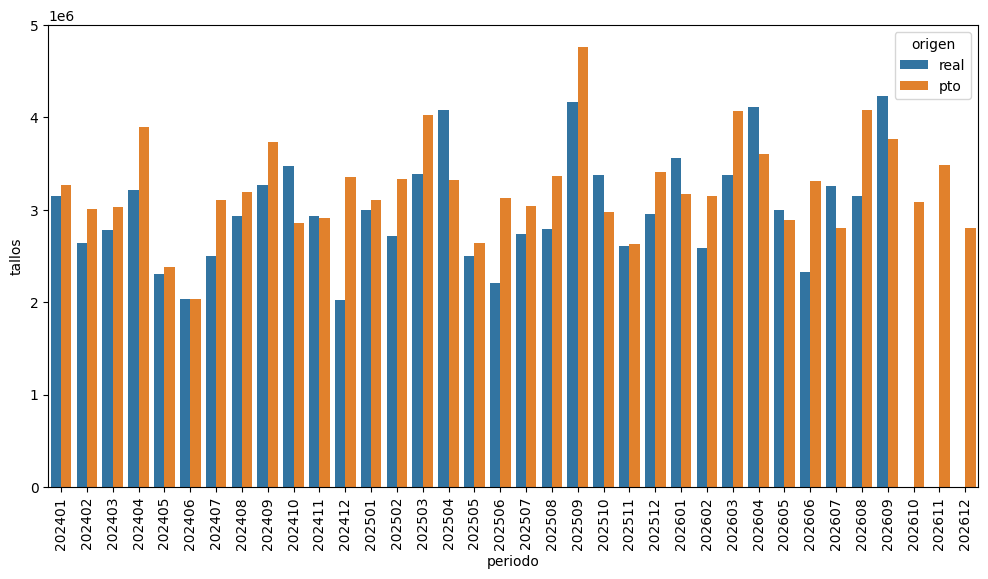

In [35]:
ax, fig = plt.subplots(figsize=(12,6))

sns.barplot(
    data=df_tidy.query("flor=='CLA' and variable=='exportable' and ano>=2024"),
    x='periodo',
    y='tallos',
    hue='origen'
)

plt.xticks(rotation=90)

plt.show()

In [36]:
df2 = df1[['ano','mes','flor','grado','produccion','expble','exptdo', 'bajas_nac','compras', 'obsequios', 'vta_nal', 'desechos',
       'inicial', 'nacional','%grado']]

In [37]:
df2.rename({'produccion':'tallos_producción','expble':'tallos_exportables','exptdo':'tallos_exportados','bajas_nac':'bajas_nacional','inicial':'inventario'},axis=1, inplace=True)

In [38]:
df2.to_excel("//svrinverpalmas/usuarios/Hilder/Data/Producción Vs Despachado.xlsx", index=False)

In [39]:
df2.tail()

,ano,mes,flor,grado,tallos_producción,tallos_exportables,tallos_exportados,bajas_nacional,compras,obsequios,vta_nal,desechos,inventario,nacional,%grado
3745,2026,9,ROC,NAL,90167.51,0.00,0.0,13475.67,0.0,104.0,9.357500e+04,7536.0,0.0,90167.51,0.141786
3746,2026,9,ROS,040,47012.41,47012.41,37036.0,0.00,0.0,0.0,-3.637979e-12,0.0,7200.0,0.00,0.135417
3747,2026,9,ROS,050,262465.42,262465.42,212558.0,0.00,0.0,75.0,1.455192e-11,0.0,43524.0,0.00,0.756018
3748,2026,9,ROS,060,1409.91,1409.91,1950.0,0.00,0.0,0.0,-1.136868e-13,0.0,4800.0,0.00,0.004061
3749,2026,9,ROS,NAL,36280.26,0.00,0.0,16594.03,0.0,0.0,4.070000e+04,9525.0,0.0,36280.26,0.104503


In [40]:
df.query("ano==2025 and mes==1").groupby('flor')['nacional'].sum()

flor
CLA    346588.48
CM0    189909.84
ROC    146140.00
ROS     86433.00
Name: nacional, dtype: float64

In [41]:
df2.query("ano==2025 and mes==2").groupby('flor')['nacional'].sum()

flor
CLA    233959.54
CM0    105885.00
ROC     59278.00
ROS     36375.00
Name: nacional, dtype: float64

# Distibuir por fincas

In [42]:
df_d = df[['ano','mes','flor','grado','produccion','expble','exptdo', 'bajas_nac','compras', 'obsequios', 'vta_nal', 'desechos',
       'inicial', 'nacional']]

In [43]:
df001 = pd.merge(
    df_d,
    df_prod[['ano','flor','mes','001','aporte001']],
    on=['ano','flor','mes'],
    how='left'
).fillna(0).reset_index(drop=True)

columnas_multiplicar = df001.columns[4:-2].tolist()
df001[columnas_multiplicar] = df001[columnas_multiplicar].multiply(df001['aporte001'],axis='index')

df001.rename({'001':'produccion_bruta'},axis=1,inplace=True)
df001['finca'] = '001'
df001.drop('aporte001',axis=1,inplace=True)

In [44]:
df002 = pd.merge(
    df_d,
    df_prod[['ano','flor','mes','002','aporte002']],
    on=['ano','flor','mes'],
    how='left'
).fillna(0).reset_index(drop=True)

columnas_multiplicar = df002.columns[4:-2].tolist()
df002[columnas_multiplicar] = df002[columnas_multiplicar].multiply(df002['aporte002'],axis='index')

df002.rename({'002':'produccion_bruta'},axis=1,inplace=True)
df002['finca'] = '002'
df002.drop('aporte002',axis=1,inplace=True)

In [45]:
dframe0 = pd.concat([df001,df002],axis=0).fillna(0)

In [46]:
dframe0.query("ano==2023 and flor=='CLA'")['produccion'].sum()

np.float64(35173844.99999999)

In [47]:
dframe0 = dframe0.query("produccion>0")

In [48]:
dframe0.head()

,ano,mes,flor,grado,produccion,expble,exptdo,bajas_nac,compras,obsequios,vta_nal,desechos,inicial,nacional,produccion_bruta,finca
0,2010,1,CLA,FAN,977305.800319,977305.800319,650196.425729,0.000000,0.0,0.000000,0.000000e+00,25489.974315,271245.774673,0.000000,1932755.0,001
1,2010,1,CLA,NAL,238792.609496,0.000000,0.000000,130281.158385,0.0,588.876415,2.877281e+05,51684.877090,32868.601991,238792.609496,1932755.0,001
2,2010,1,CLA,SEL,271054.705971,271054.705971,498046.876781,0.000000,0.0,0.000000,0.000000e+00,15947.244412,77979.634708,0.000000,1932755.0,001
3,2010,1,CLA,SHR,13404.686809,13404.686809,12893.294133,0.000000,0.0,0.000000,0.000000e+00,0.000000,0.000000,0.000000,1932755.0,001
4,2010,1,CLA,STD,282136.610054,282136.610054,203893.809575,0.000000,0.0,0.000000,9.020294e-12,11870.229840,62141.958502,0.000000,1932755.0,001


In [49]:
dfareas.head()

,finca,bloque,flor,variedad,mes,pre,pro,metros,ano
0,001,21,CLA,,1,0.0,0.0,4300,2010
1,001,23,CLA,,1,0.0,0.0,6400,2010
2,001,26,CLA,,1,0.0,0.0,5300,2010
3,001,29,CLA,,1,0.0,0.0,3500,2010
4,001,30,CLA,,1,0.0,0.0,6100,2010


In [50]:
dframe1 = pd.merge(
    dframe0,
    df_areas,
    on=['finca','flor','ano','mes'],
    how='left'
)
#Aqui se agregó metros

In [51]:
dframe2 = pd.merge(
    dframe1,
    df_pto,
    on=['finca','flor','ano','mes'],
    how='left'
)
#aquí se agrego pto

In [52]:
dframe3 = pd.merge(
    dframe2,
    df_matas,
    on=['finca','flor','ano','mes'],
    how='left'
)
#aquí se agregó matas

In [53]:
dframe3.tail()

,ano,mes,flor,grado,produccion,expble,exptdo,bajas_nac,compras,obsequios,vta_nal,desechos,inicial,nacional,produccion_bruta,finca,metros,presupuesto,matas
5544,2026,9,CLA,STD,21677.237252,21677.237252,24574.465100,0.000000,0.0,0.000000,4.399674e-13,0.000000,2902.495878,0.000000,2320172.0,002,83748,1985139,1736059
5545,2026,9,CM0,FAN,550170.712209,550170.712209,496243.645103,0.000000,0.0,118.267198,1.147343e-11,0.000000,49900.873220,0.000000,1304801.0,002,50591,1081139,881101
5546,2026,9,CM0,NAL,78662.430874,0.000000,0.000000,21586.184233,0.0,3.153792,9.820120e+04,196.323549,0.000000,78662.430874,1304801.0,002,50591,1081139,881101
5547,2026,9,CM0,SEL,654882.392349,654882.392349,663651.652802,0.000000,0.0,0.000000,4.015700e-11,0.000000,26964.921222,0.000000,1304801.0,002,50591,1081139,881101
5548,2026,9,CM0,STD,2081.502691,2081.502691,1135.365104,0.000000,0.0,0.000000,0.000000e+00,0.000000,946.137587,0.000000,1304801.0,002,50591,1081139,881101


In [54]:
# Calcular la suma total de producción por grupo de año, mes, finca y flor
dframe3['aporte'] = dframe3.groupby(['ano', 'mes', 'finca', 'flor'])['produccion'].transform(lambda x: x/x.sum())

In [55]:
cols_multiply = ['produccion_bruta','metros','presupuesto','matas']
dframe3[cols_multiply] = dframe3[cols_multiply].multiply(dframe3.aporte,axis='index')

In [56]:
#Aquí eliminamos grado y nos vamos a finca, flor, ano y mes

In [57]:
# Definir las columnas por las cuales quieres agrupar
columnas_agrupadas = ['ano', 'mes', 'flor', 'finca']
#eliminar columnas que no se quieren incluir
dframe3.drop(['grado','aporte'],axis=1,inplace=True)
# Sumar todas las demás columnas
columnas_a_sumar = dframe3.columns.difference(columnas_agrupadas)
# Agrupar por las columnas especificadas y sumar el resto
dframe4 = dframe3.groupby(columnas_agrupadas)[columnas_a_sumar].sum().reset_index()

In [58]:
dframe7 = dframe4.groupby(
    ['flor','ano','mes']
).agg(
    {'produccion':np.sum,'expble':np.sum,'exptdo':np.sum,'nacional':np.sum,'matas':np.sum,'metros':np.sum,'presupuesto':np.sum}
).reset_index()

#Porcentaje de nacional
dframe7['%nacional'] = dframe7['nacional'] / dframe7['produccion']
dframe7.drop(columns=['nacional'], inplace=True)

#Hallar flor mata
dframe7['FMata_produccion'] = dframe7['produccion'] / dframe7['matas']
dframe7['FMata_expble'] = dframe7['expble'] / dframe7['matas']
dframe7['FMata_exptdo'] = dframe7['exptdo'] / dframe7['matas']

#hallar flor metro 2
dframe7['FM2_produccion'] = dframe7['produccion'] / dframe7['metros']
dframe7['FM2_expble'] = dframe7['expble'] / dframe7['metros']
dframe7['FM2_exptdo'] = dframe7['exptdo'] / dframe7['metros']

dframe7['finca'] = '000'

In [59]:
dframe5 = dframe4.groupby(
    ['finca','flor','ano','mes']
).agg(
    {'produccion':np.sum,'expble':np.sum,'exptdo':np.sum,'nacional':np.sum,'matas':np.sum,'metros':np.sum,'produccion':np.sum}
).reset_index()

#Porcentaje de nacional
dframe5['%nacional'] = dframe5['nacional'] / dframe5['produccion']
dframe5.drop(columns=['nacional'], inplace=True)

#Hallar flor mata
dframe5['FMata_produccion'] = dframe5['produccion'] / dframe5['matas']
dframe5['FMata_expble'] = dframe5['expble'] / dframe5['matas']
dframe5['FMata_exptdo'] = dframe5['exptdo'] / dframe5['matas']

#hallar flor metro 2
dframe5['FM2_produccion'] = dframe5['produccion'] / dframe5['metros']
dframe5['FM2_expble'] = dframe5['expble'] / dframe5['metros']
dframe5['FM2_exptdo'] = dframe5['exptdo'] / dframe5['metros']

### Exportar a excel

In [60]:
#unir
dframe_end = pd.concat(
    [dframe5,dframe7],
    axis=0
)

In [61]:
dframe_end.to_excel("C:/Users/Estadistica/Downloads/base.xlsx", index=False)

### Derretimiento

In [62]:
dframe10 = dframe_end.groupby(
    ['finca','flor','ano','mes']
).agg(
    {
     'presupuesto':np.sum,
     'produccion':np.sum,
     'expble':np.sum,
     'exptdo':np.sum,
     'FMata_produccion':np.sum,
     'FMata_expble':np.sum,
     'FMata_exptdo':np.sum,
     'FM2_produccion':np.sum,
     'FM2_expble':np.sum,
     'FM2_exptdo':np.sum
    }
).reset_index()

In [63]:
# Crear DataFrames separados para cada grupo de columnas y derretirlos
grupo_produccion = dframe10.melt(id_vars=['finca', 'flor', 'ano','mes'], value_vars=['presupuesto','produccion', 'expble', 'exptdo'], var_name='variable', value_name='valor')
grupo_FMata = dframe10.melt(id_vars=['finca', 'flor', 'ano','mes'], value_vars=['FMata_produccion', 'FMata_expble', 'FMata_exptdo'], var_name='variable', value_name='valor')
grupo_FM2 = dframe10.melt(id_vars=['finca', 'flor', 'ano','mes'], value_vars=['FM2_produccion', 'FM2_expble', 'FM2_exptdo'], var_name='variable', value_name='valor')

# Unir los DataFrames
resultado_final = pd.concat([grupo_produccion, grupo_FMata, grupo_FM2])

In [64]:
resultado_final.tail()

,finca,flor,ano,mes,variable,valor
6025,002,CM0,2026,5,FM2_exptdo,11.595182
6026,002,CM0,2026,6,FM2_exptdo,14.132009
6027,002,CM0,2026,7,FM2_exptdo,16.951789
6028,002,CM0,2026,8,FM2_exptdo,17.522513
6029,002,CM0,2026,9,FM2_exptdo,22.949352


In [65]:
resultado_final.to_excel("//svrinverpalmas/usuarios/Hilder/Data/Datos de exportado.xlsx", index=False)

In [66]:
2+2

4